# hst_corpus_70m Cell Graph

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.02.2025
- Date of Last Modification: 24.02.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [23]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
import sys
sys.path.append("../../utils")

In [25]:
import logging
import os
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from datasets import load_from_disk
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [27]:
# Set params
dataset = 'hst_corpus_70m'
tokenizer = 'cell_graph'
load_timestamp = '26022025_070322_952' # counts
# load_timestamp = '20022025_082432_404' # rank
read_checkpoint = 'nichejepa-ep2.pth.tar'
niche_key = 'niche_type'

In [28]:
model_config_folder_path = '../../config/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

In [29]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

In [30]:
# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{tokenizer}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'batch_size': 128,
  'dataset_name': 'hst_corpus_70m',
  'n_segments': 11,
  'num_workers': 24,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_train.pkl',
  'precomputed_split': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_split_train.pkl',
  'random_state': 0,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m',
  'sample_subset': False,
  'sampling_strategy': None,
  'seq_len_cell': 64,
  'seq_len_neighborhood': 640,
  'split': 0,
  'stratify': False,
  'token_dict_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/gold/cell-graph-tokenizer/hst_corpus_70m/hst_corpus_70m_32_None_Non

In [31]:
# Define folder path for saving and loading artifacts
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/hst_corpus_70m/26022025_070322_952'

# 2. Analysis

In [32]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'

## 2.1 Full Corpus

In [33]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [34]:
# Load dataset
dataset = load_from_disk(params['data']['tokenized_data_folder_path'])

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]


KeyboardInterrupt



In [ ]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.5 # 0.1, 0.5
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [ ]:
# Subset dataset
step_size = 2000000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

del dataset

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i >= 10:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 10:
        continue
    if i >= 20:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i < 20:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  uns_cols=['assay', 'tissue'],
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')
    del adata

## 2.2 Benchmarking Test Sets

### 2.2.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

In [82]:
# load_timestamp = '19022025_023508_679' # counts
# read_checkpoint = 'nichejepa-ep3.pth.tar'
# NMI = 0.x, ARI = 0.x

#### 2.2.1.1 Define Config

In [83]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '59_batch0',
    #'59_batch3', # unannotated
    '59_batch6',
    '59_batch7',
    #'59_batch2', # unannotated
    '59_batch4',
    '59_batch1',
    '59_batch5']
params['data']['val_batch_ids'] = None

In [84]:
# Set dataset params
dataset_name = 'chl59-8b_1p'
niche_key = 'niche'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(params['data']['test_batch_ids'])

#### 2.2.1.2 Run Model Inference

In [85]:
# Load data
_, _, test_dataset = prepare_dataset(params)
test_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 598585
})

In [86]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(117, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 1024

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
4677it [41:28,  1.88it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['59'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/chl59-8b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [87]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

#### 2.2.1.3 Identify Niches

In [88]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.2
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

Number of latent clusters 9


IOStream.flush timed out


Number of latent clusters 10


IOStream.flush timed out
IOStream.flush timed out


Number of latent clusters 9
Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 9
Number of latent clusters 10
Number of latent clusters 9
Number of latent clusters 10
Number of latent clusters 9
Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 9
Number of latent clusters 9


#### 2.2.1.4 Plot Embedding Similarity Stats

In [ ]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key=niche_key,
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)

### 2.2.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [60]:
# load_timestamp = '19022025_023508_679' # counts
# read_checkpoint = 'nichejepa-ep3.pth.tar'
# NMI = 0.333, ARI = 0.152

#### 2.2.2.1 Define Config

In [61]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '78_batch3',
    '78_batch10',
    '78_batch1',
    '78_batch0',
    '78_batch2',
    '78_batch6',
    '78_batch7',
    '78_batch9',
    '78_batch8',
    '78_batch4',
    '78_batch5']
params['data']['val_batch_ids'] = None

In [80]:
# Set dataset params
niche_key = 'broad_anatomy'
batch_key = 'batch'
spot_sizes = [1920 * 0.093] * len(params['data']['test_batch_ids'])

#### 2.2.2.2 Run Model Inference

In [63]:
# Load data
_, _, test_dataset = prepare_dataset(params)
test_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 325816
})

In [64]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(117, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 1024

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
2546it [22:47,  1.86it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['78'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/chr78-11b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [65]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

#### 2.2.2.3 Identify Niches

In [66]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

Number of latent clusters 27
Number of latent clusters 27
Number of latent clusters 22
Number of latent clusters 21
NMI is 0.46785142458619405. ARI is 0.2624369051715152.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
... storing 'batch' as categorical
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax =

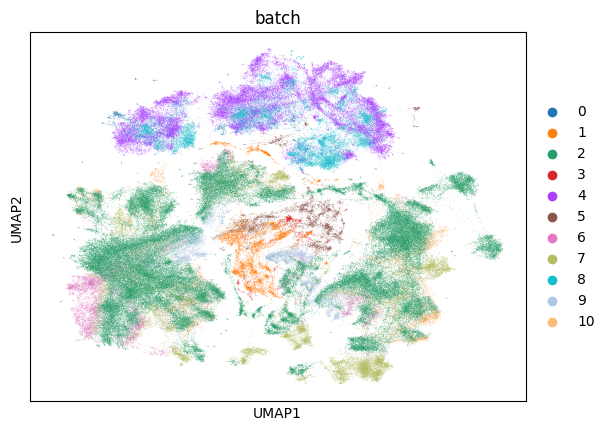

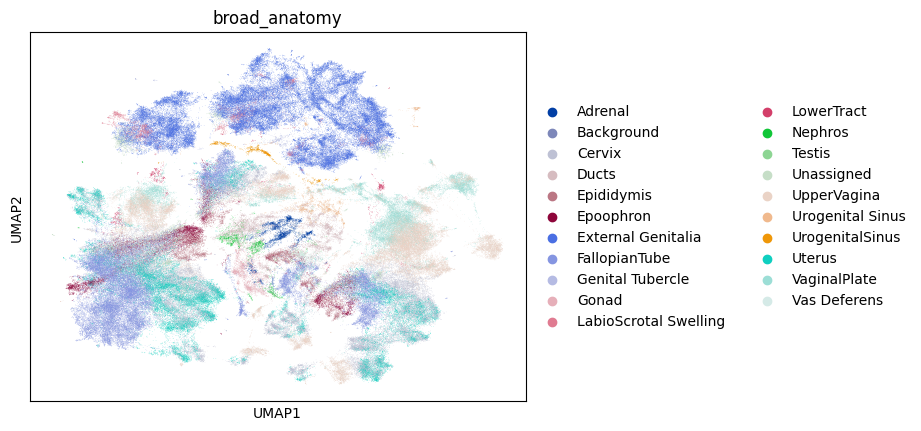

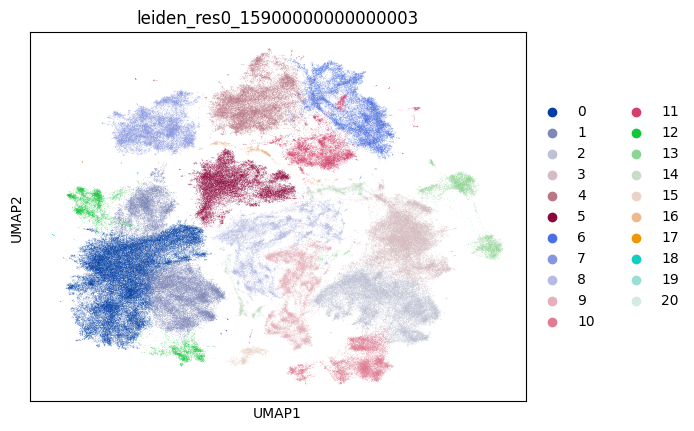

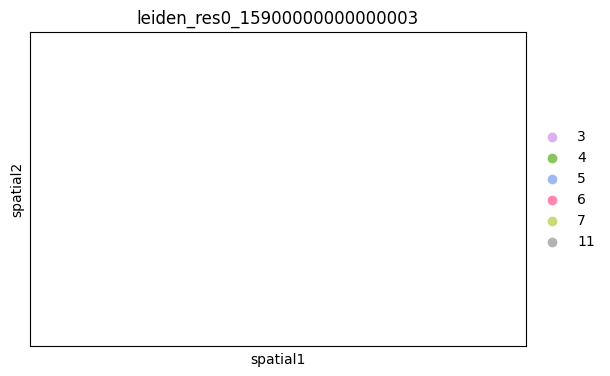

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


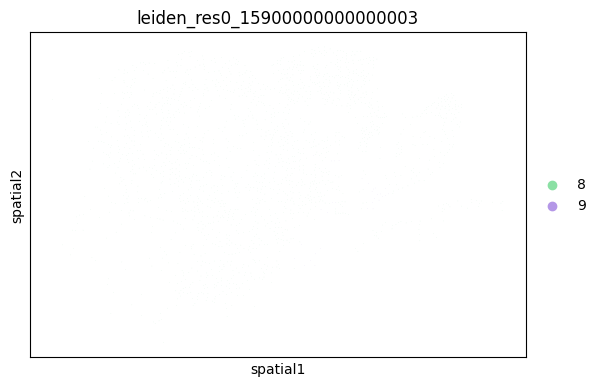

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


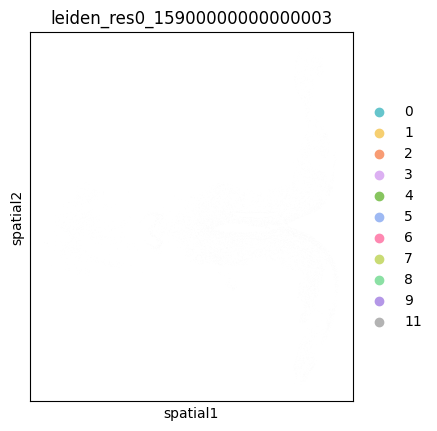

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


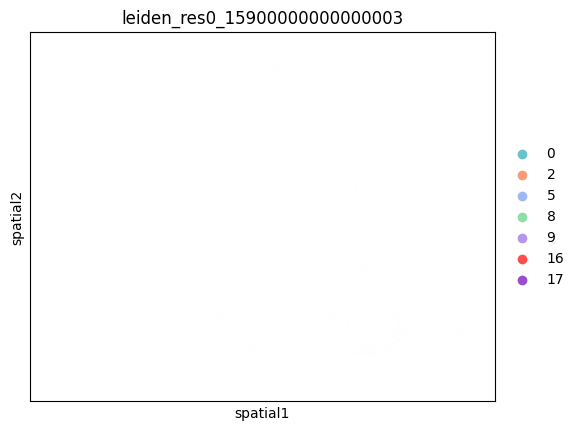

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


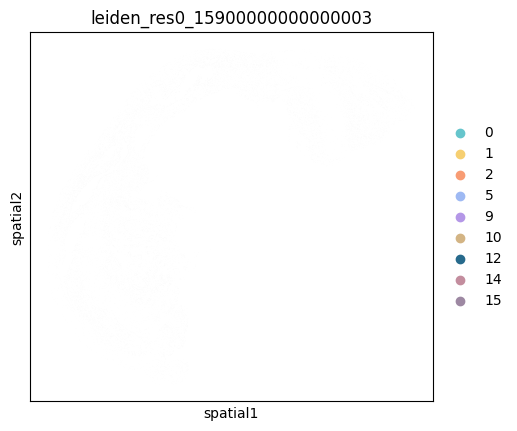

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


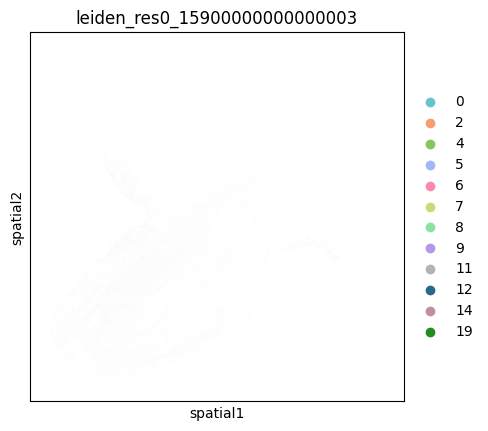

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


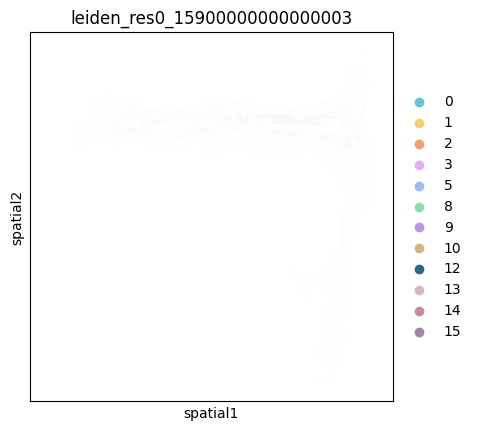

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


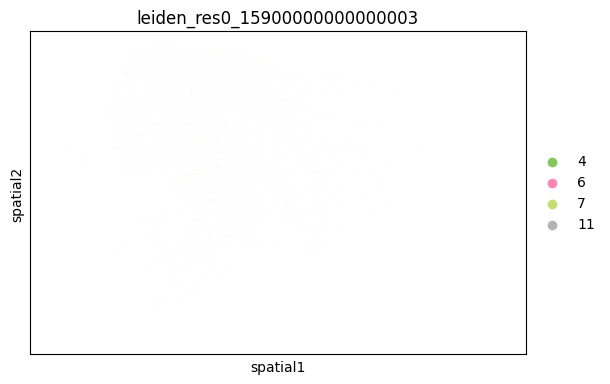

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


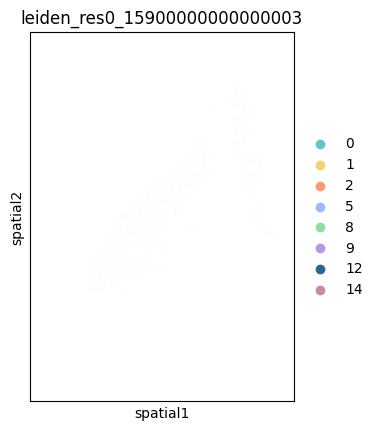

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


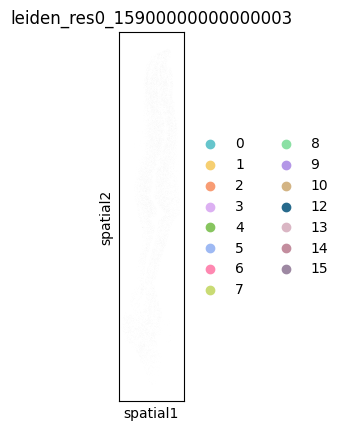

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


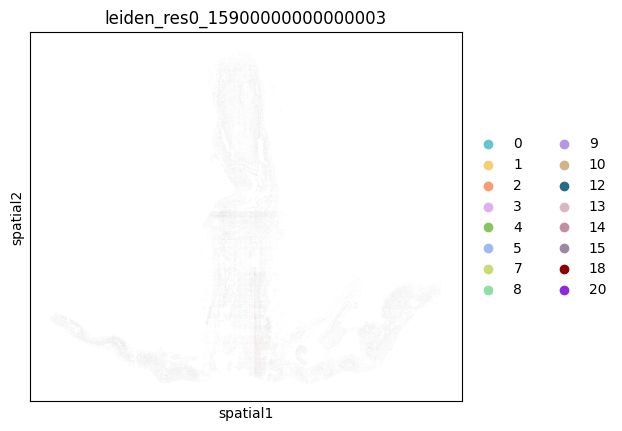

In [67]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.2
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


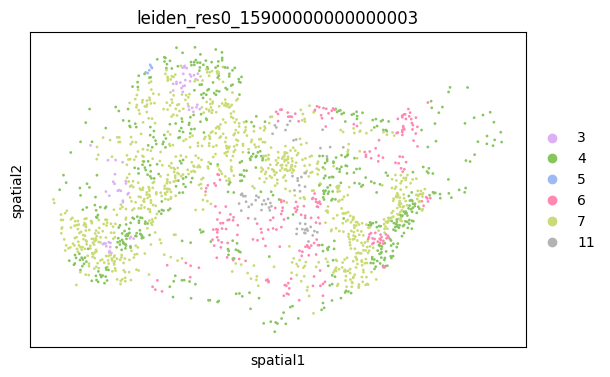

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


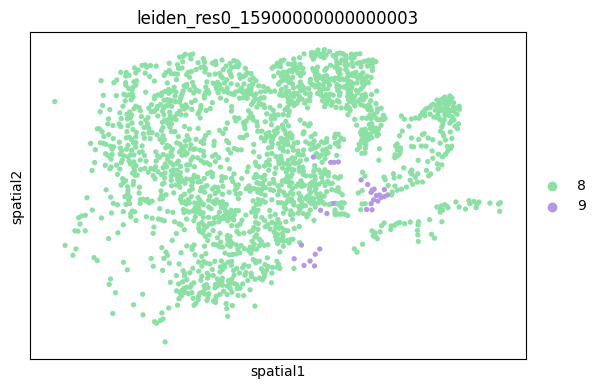

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


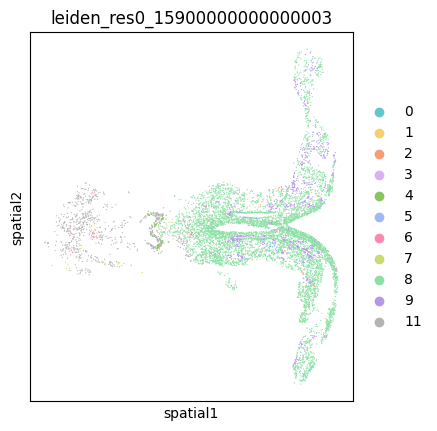

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


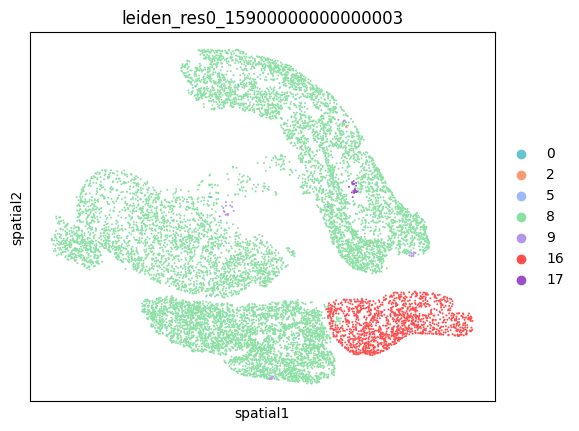

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


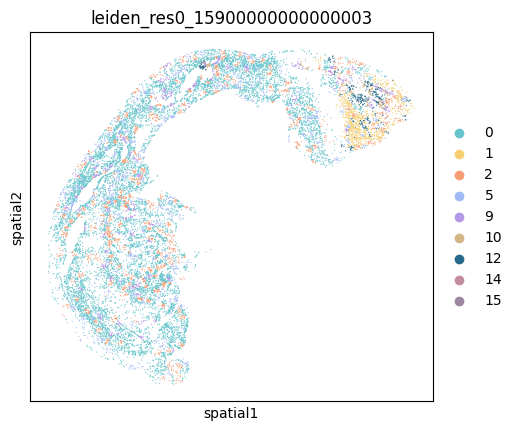

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


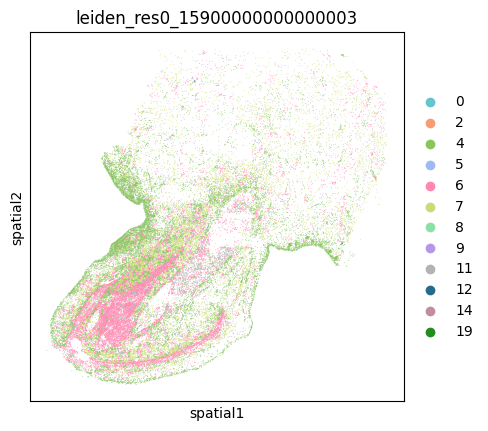

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


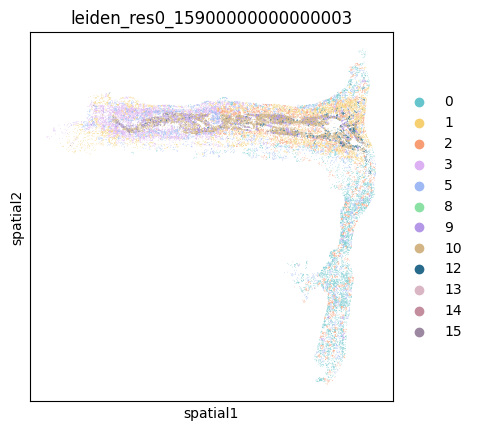

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


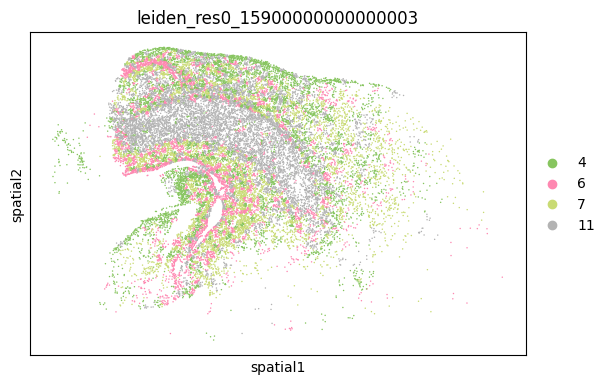

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


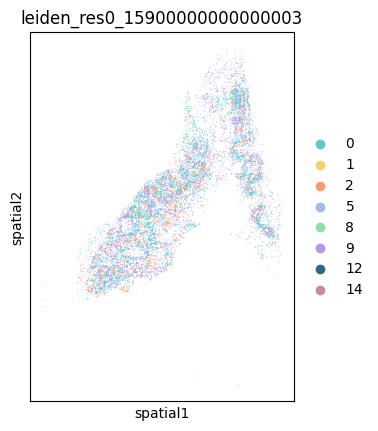

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


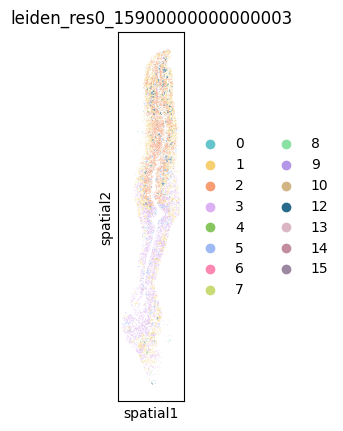

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


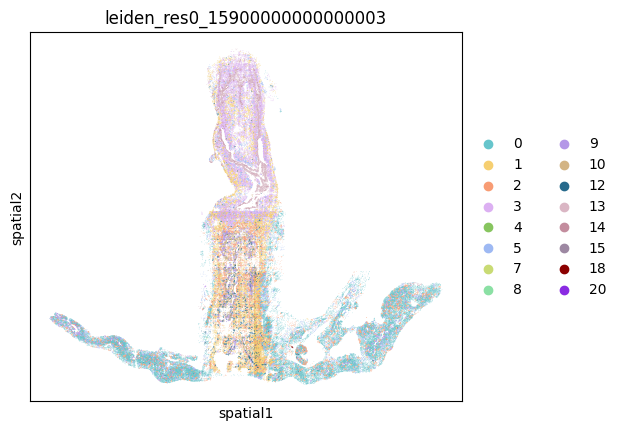

In [81]:
# Plot niches in tissue
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

In [78]:
spot_sizes

[89.28, 89.28, 89.28, 89.28, 89.28, 89.28, 89.28, 89.28, 89.28, 89.28, 89.28]

#### 2.2.2.4 Plot Embedding Similarity Stats

                   Class 1                Class 2  Mean Similarity  \
0    LabioScrotal Swelling  LabioScrotal Swelling         0.867919   
1    LabioScrotal Swelling       Genital Tubercle         0.838299   
2    LabioScrotal Swelling                  Gonad         0.786211   
3    LabioScrotal Swelling                Adrenal         0.774693   
4    LabioScrotal Swelling                  Ducts         0.789074   
..                     ...                    ...              ...   
436             Epididymis                 Cervix         0.734940   
437             Epididymis             LowerTract         0.740306   
438             Epididymis                 Testis         0.797229   
439             Epididymis           Vas Deferens         0.788136   
440             Epididymis             Epididymis         0.824114   

     Variance Similarity  
0               0.002732  
1               0.002560  
2               0.002492  
3               0.003327  
4               0.003394

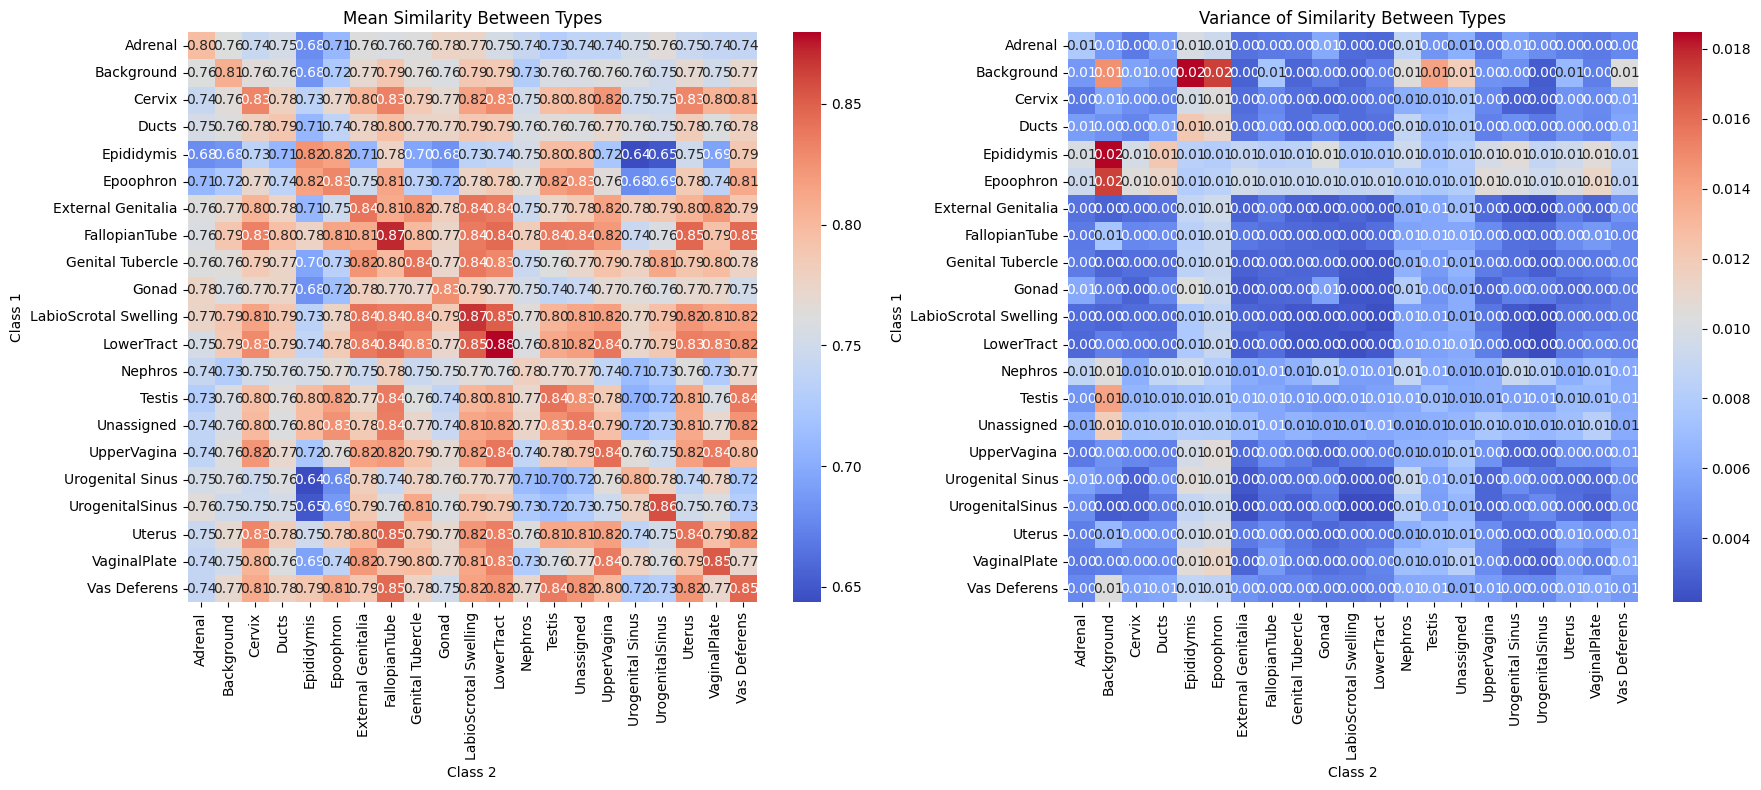

In [68]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key=niche_key,
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)

### 2.2.3 xhs49-1b_1p (Xenium Human Melanoma)

In [51]:
# load_timestamp = '19022025_023508_679' # counts
# read_checkpoint = 'nichejepa-ep3.pth.tar'
# NMI = 0.372, ARI = 0.237

# load_timestamp = '19022025_023508_679' # counts
# read_checkpoint = 'nichejepa-ep3.pth.tar'
# NMI = 0.372, ARI = 0.237

#### 2.2.2.1 Define Config

In [52]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '49_batch0']
params['data']['val_batch_ids'] = None

In [53]:
# Set dataset params
niche_key = 'niche_name'
spot_size = 20

#### 2.2.3.2 Run Model Inference

In [54]:
# Load data
_, _, test_dataset = prepare_dataset(params)
test_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 109208
})

In [55]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(117, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 1024

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
854it [07:45,  1.84it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['49'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhs49-1b_1p.


In [56]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

#### 2.2.3.3 Identify Niches

In [57]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

Number of latent clusters 6
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 6
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 5
Number of latent clusters 6
NMI is 0.4775746186004746. ARI is 0.37006020271681234.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
... storing 'batch' as categorical
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax =

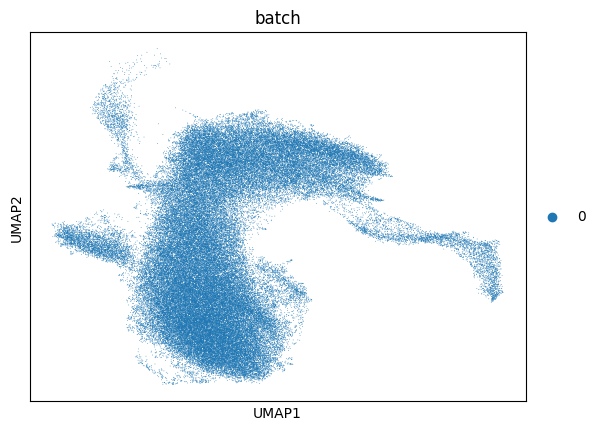

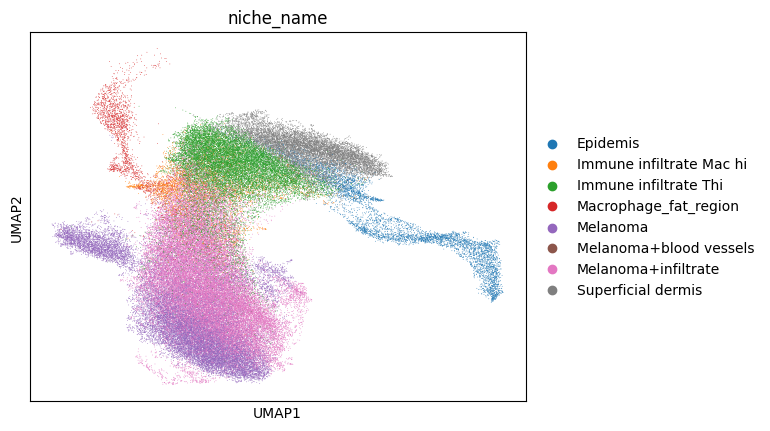

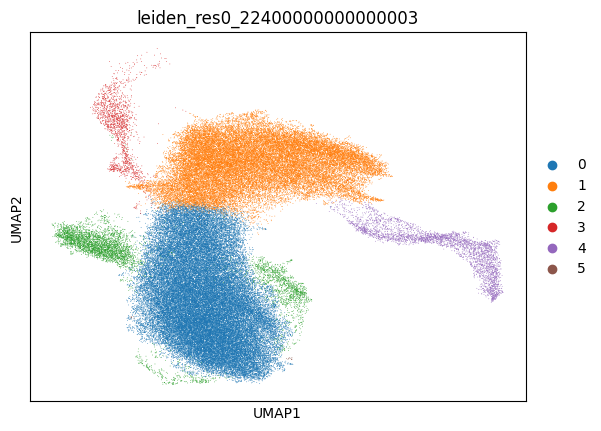

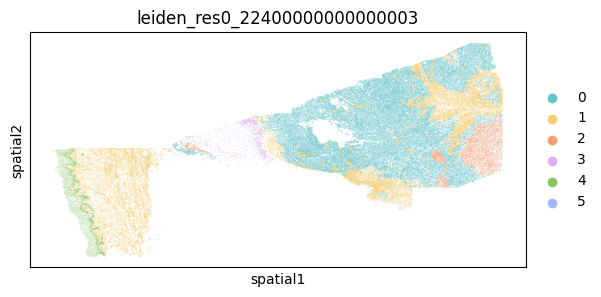

In [58]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.2
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

#### 2.2.3.4 Plot Embedding Similarity Stats

                   Class 1                   Class 2  Mean Similarity  \
0                 Epidemis                  Epidemis         0.837766   
1                 Epidemis        Superficial dermis         0.804601   
2                 Epidemis       Melanoma+infiltrate         0.844655   
3                 Epidemis                  Melanoma         0.843919   
4                 Epidemis     Immune infiltrate Thi         0.794198   
..                     ...                       ...              ...   
59  Melanoma+blood vessels                  Melanoma         0.933550   
60  Melanoma+blood vessels     Immune infiltrate Thi         0.925804   
61  Melanoma+blood vessels  Immune infiltrate Mac hi         0.933407   
62  Melanoma+blood vessels     Macrophage_fat_region         0.896068   
63  Melanoma+blood vessels    Melanoma+blood vessels         0.965741   

    Variance Similarity  
0              0.012098  
1              0.015904  
2              0.004189  
3              0.00

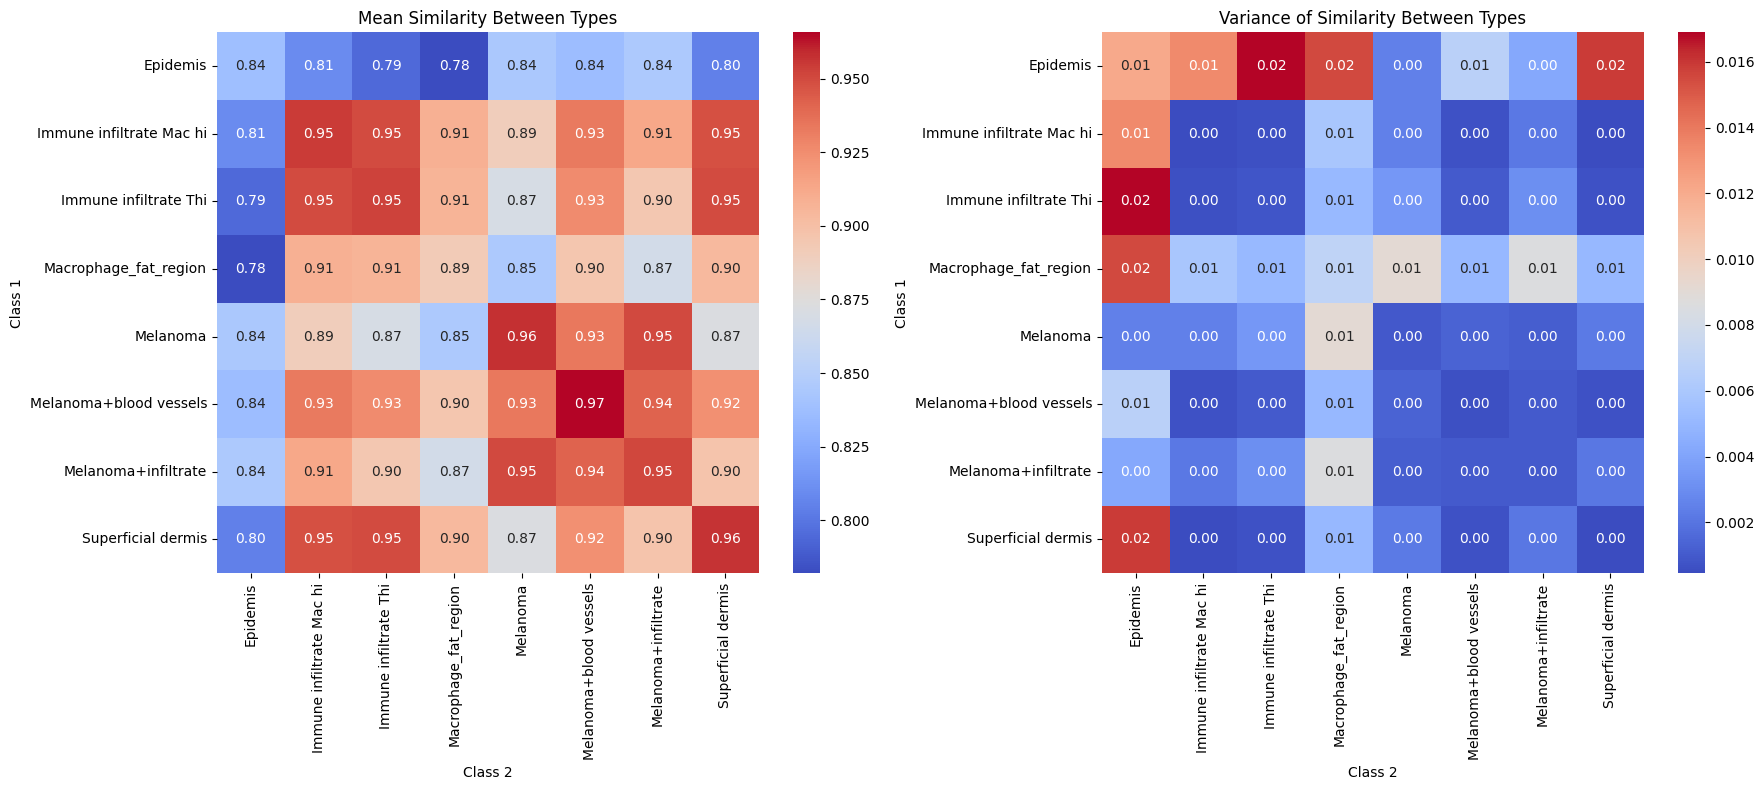

In [59]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key=niche_key,
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)

### 2.2.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

In [35]:
# load_timestamp = '19022025_023508_679' # counts
# read_checkpoint = 'nichejepa-ep3.pth.tar'
# NMI = 0.576, ARI = 0.372

#### 2.2.4.1 Define Config

In [36]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '1000_batch11',
    '1000_batch19',
    '1000_batch32']
params['data']['val_batch_ids'] = None

In [37]:
# Set dataset params
dataset_name = 'xhs1000-39b_1p'
niche_key = 'niche_type'
batch_key = 'sample'
spot_sizes = [20] * len(params['data']['test_batch_ids'])

#### 2.2.4.2 Run Model Inference

In [38]:
# Load data
_, _, test_dataset = prepare_dataset(params)
test_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 53655
})

In [39]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(117, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 1024

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
420it [04:06,  1.70it/s]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading datasets: ['1000'].
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhs1000-39b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_un

In [40]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

#### 2.2.4.3 Identify Niches

In [42]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

Number of latent clusters 16
Number of latent clusters 14
Number of latent clusters 14
Number of latent clusters 14
Number of latent clusters 13
Number of latent clusters 14
Number of latent clusters 15
Number of latent clusters 13
Number of latent clusters 13
Number of latent clusters 14
Number of latent clusters 12
NMI is 0.569932098251196. ARI is 0.3536088748740471.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  

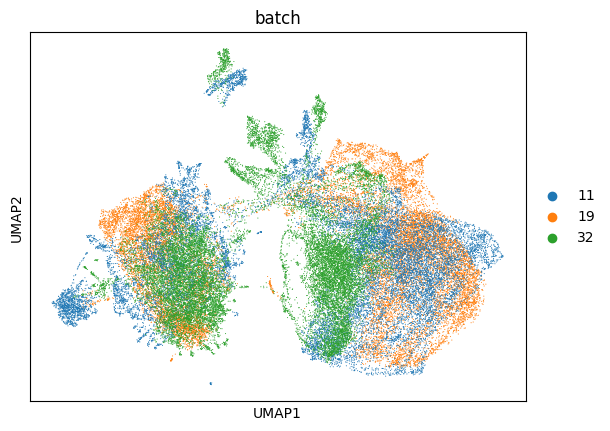

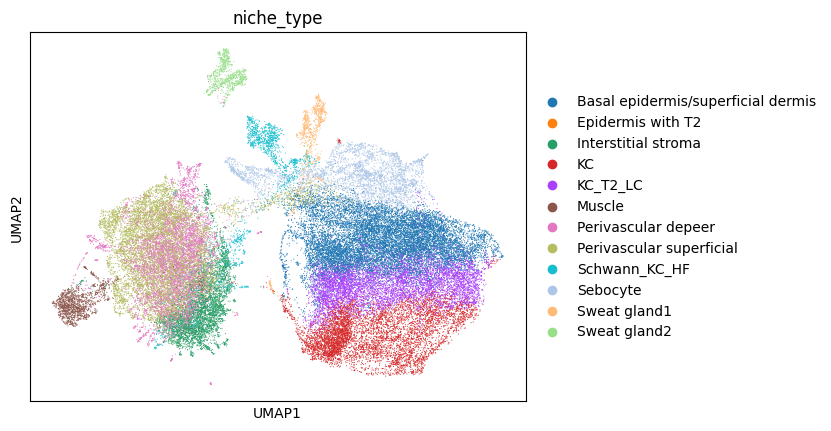

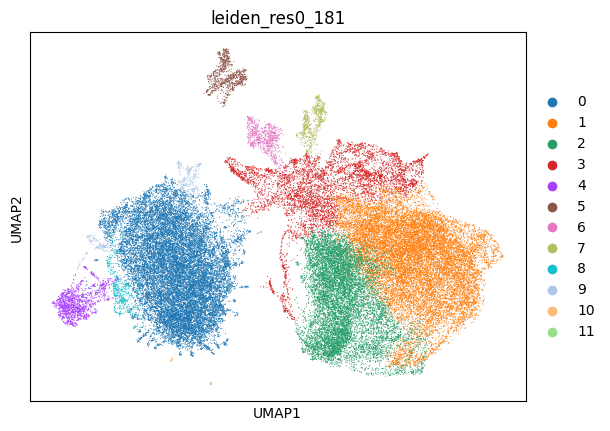

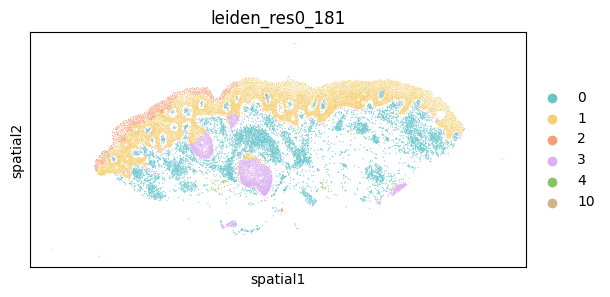

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


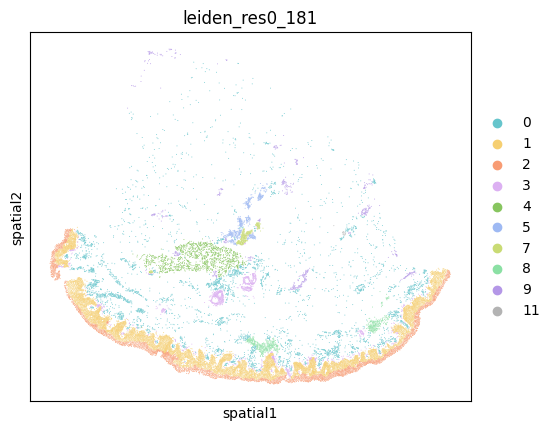

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


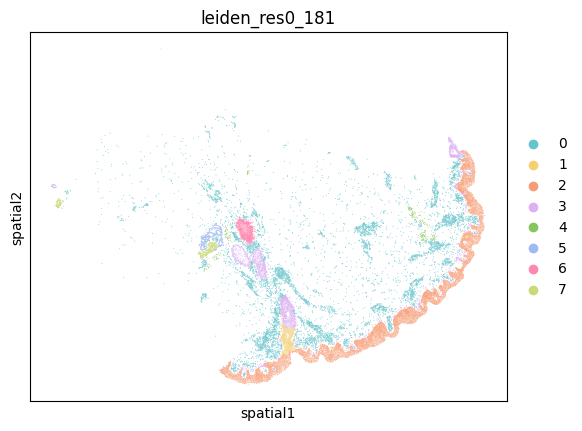

In [50]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.2
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

#### 2.2.4.4 Plot Embedding Similarity Stats

                                Class 1                             Class 2  \
0    Basal epidermis/superficial dermis  Basal epidermis/superficial dermis   
1    Basal epidermis/superficial dermis                            KC_T2_LC   
2    Basal epidermis/superficial dermis                                  KC   
3    Basal epidermis/superficial dermis            Perivascular superficial   
4    Basal epidermis/superficial dermis                 Interstitial stroma   
..                                  ...                                 ...   
139                   Epidermis with T2                       Schwann_KC_HF   
140                   Epidermis with T2                              Muscle   
141                   Epidermis with T2                        Sweat gland1   
142                   Epidermis with T2                        Sweat gland2   
143                   Epidermis with T2                   Epidermis with T2   

     Mean Similarity  Variance Similarity  
0      

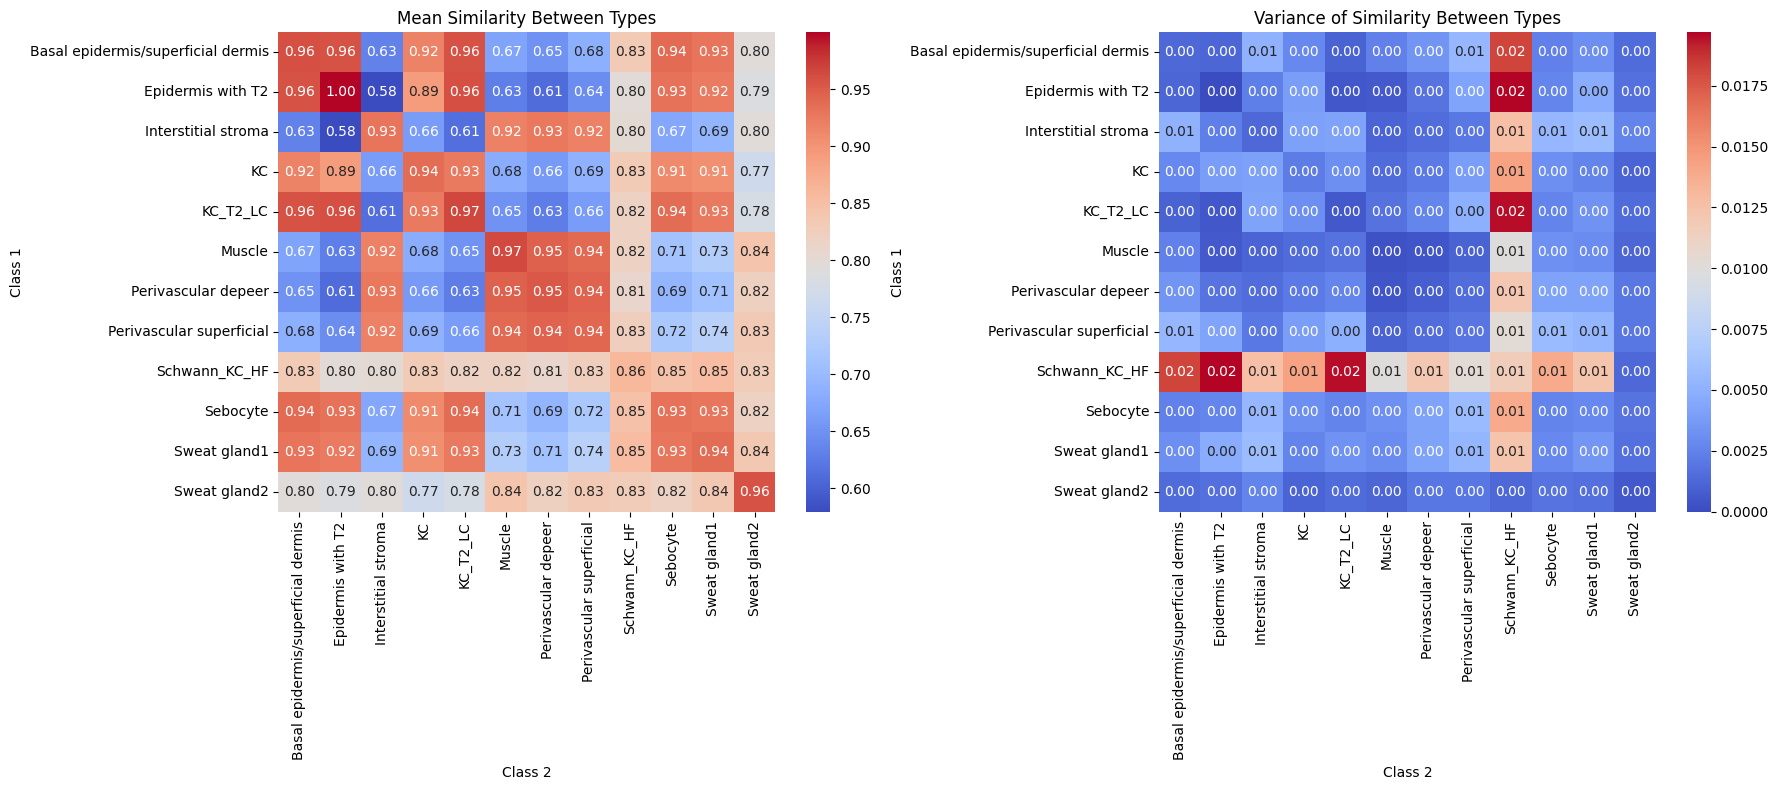

In [41]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key=niche_key,
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)